In [14]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, Dropout
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling1D
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow Version: 2.21.0
Libraries imported successfully!


In [15]:

vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Dataset loaded successfully!")


Training samples: 25000
Testing samples: 25000
Dataset loaded successfully!


In [16]:

model = Sequential([
    Embedding(vocab_size, 64, input_length=max_length),

    GlobalAveragePooling1D(),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(32, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ ?                      │   0 (unbuilt) │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)


Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.7793 - loss: 0.4527 - val_accuracy: 0.8638 - val_loss: 0.4986
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8917 - loss: 0.2761 - val_accuracy: 0.8756 - val_loss: 0.3110
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9174 - loss: 0.2159 - val_accuracy: 0.8780 - val_loss: 0.3176
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9340 - loss: 0.1766 - val_accuracy: 0.8680 - val_loss: 0.3649


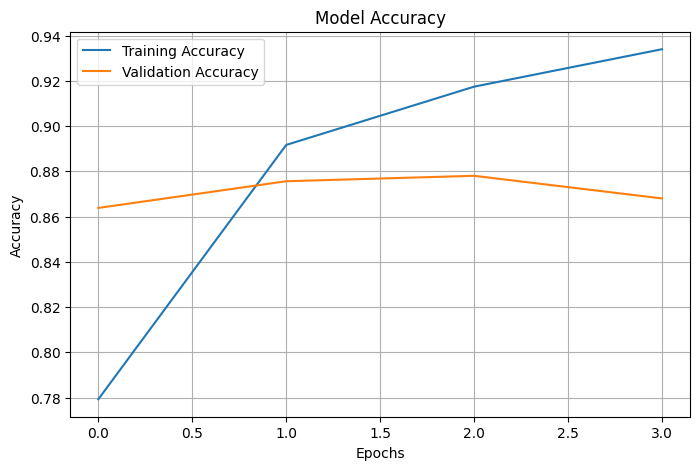

In [19]:

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()


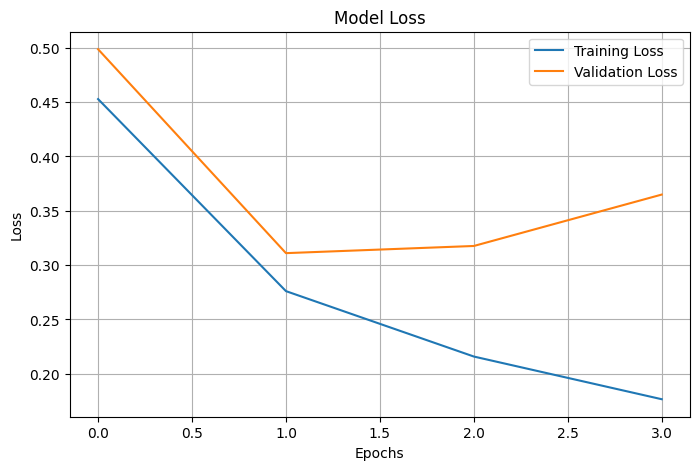

In [21]:

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()


In [25]:

import re

word_index = imdb.get_word_index()

def predict_sentiment(text):
    words = re.sub(r"[^a-zA-Z']", " ", text.lower()).split()

    sequence = [1] + [
        word_index[word] + 3 if word in word_index else 2
        for word in words
    ]

    sequence = pad_sequences(
        [sequence], maxlen=max_length
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"
    confidence = prediction if prediction >= 0.5 else 1 - prediction

    print("Review:", text)
    print("Sentiment:", sentiment)
    print("Confidence:", round(float(confidence) * 100, 2), "%")

predict_sentiment("This movie is amazing and wonderful")
predict_sentiment("This movie is boring and terrible")


Review: This movie is amazing and wonderful
Sentiment: Positive
Confidence: 80.29 %
Review: This movie is boring and terrible
Sentiment: Negative
Confidence: 58.34 %


In [24]:

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))


782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8640 - loss: 0.3281
Test Accuracy: 86.4 %
Test Loss: 0.3281
